In [1]:
import numpy as np  
import matplotlib.pyplot as plt
import os

import sys
sys.path.append("/home/mnex/Desktop/1DV_FD/LOTUS")
from mld_obs import met_start_day, read_lotus_vel

In [ ]:
MET_FILE  = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusmet.epic'
VEL_FILE = '/home/mnex/Desktop/1DV_FD/LOTUS/obs/lotusnsvel.epic'
N_DAYS = 160

In [3]:
def daily_mean(t, x, n_days):
    x = np.ma.filled(np.asarray(x, dtype=np.float64), np.nan)  # handles netCDF masked arrays
    day = np.floor(np.asarray(t)).astype(int)

    in_range = (day >= 0) & (day < n_days)
    day, x = day[in_range], x[in_range]

    finite = np.isfinite(x)
    sums   = np.zeros((n_days,) + x.shape[1:])
    counts = np.zeros((n_days,) + x.shape[1:])
    np.add.at(sums,   day, np.where(finite, x, 0.0))
    np.add.at(counts, day, finite)

    with np.errstate(invalid='ignore', divide='ignore'):
        out = np.where(counts > 0, sums / counts, np.nan)

    return np.arange(n_days) + 0.5, out

In [4]:
# --- Observations ---
t0_day = met_start_day(MET_FILE)
t_vel, z_vel, u_obs, v_obs = read_lotus_vel(VEL_FILE, t0_day, N_DAYS)

t_vel_d, u_obs_d = daily_mean(t_vel, u_obs, N_DAYS)
t_vel_d, v_obs_d = daily_mean(t_vel, v_obs, N_DAYS)

6642 velocity profiles still incomplete after filling


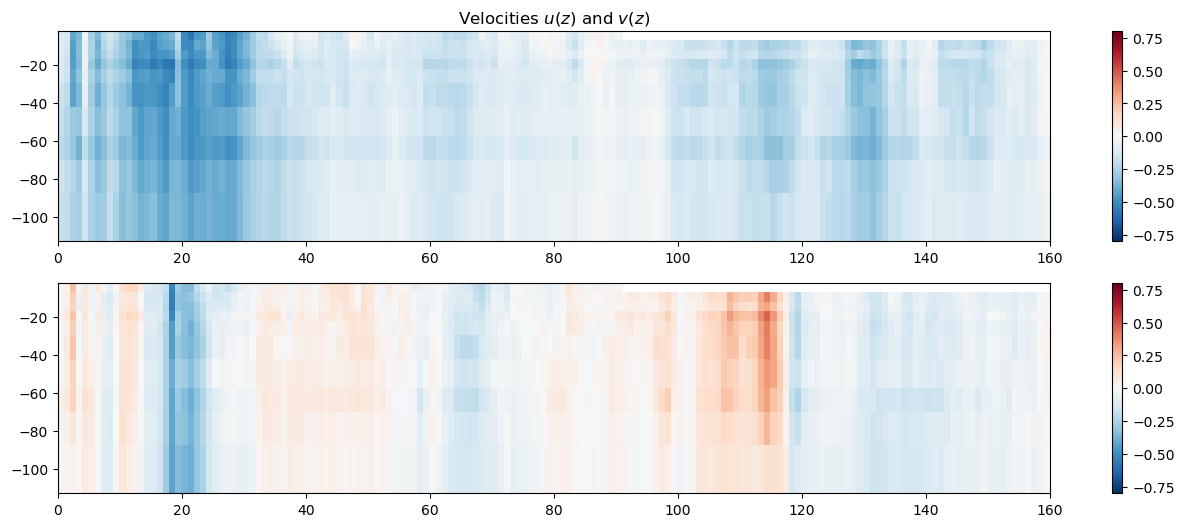

In [10]:
plt.figure(figsize= (16, 6))

plt.subplot(211)
plt.title(r"Velocities $u(z)$ and $v(z)$")
plt.pcolor(t_vel_d, -z_vel, u_obs_d.T, cmap = 'RdBu_r', vmin = -0.8, vmax = 0.8)
plt.colorbar()

plt.subplot(212)
plt.pcolor(t_vel_d, -z_vel, v_obs_d.T, cmap = 'RdBu_r', vmin = -0.8, vmax = 0.8)
plt.colorbar()

Text(0.5, 0.92, 'LOTUS — day 0.5')

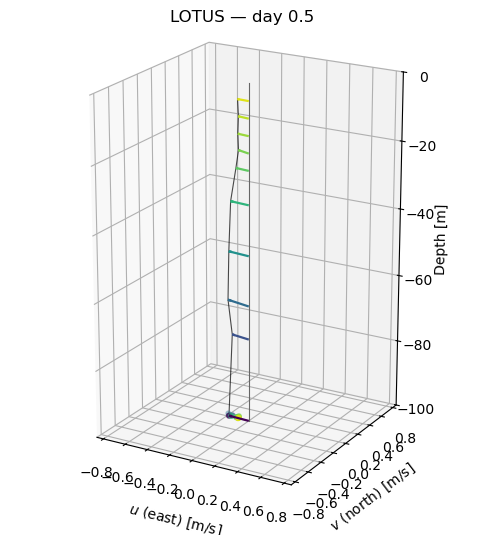

In [26]:
kt = 0

u, v = u_obs_d[kt], v_obs_d[kt]
z = -np.asarray(z_vel, dtype=float)
ok = np.isfinite(u) & np.isfinite(v)

vmax = 1.1 * np.nanmax(np.hypot(u_obs_d, v_obs_d))
fig, ax = plt.subplots(figsize=(6, 7), subplot_kw={'projection': '3d'})

zmin = z.min()
cm = plt.get_cmap('viridis')
norm = plt.Normalize(zmin, 0.0)

# Mooring line
ax.plot([0, 0], [0, 0], [zmin, 0], color='0.4', lw=0.8)

# Arrows, coloured by depth
for ui, vi, zi in zip(u[ok], v[ok], z[ok]):
    ax.quiver(0, 0, zi, ui, vi, 0, color=cm(norm(zi)),
                arrow_length_ratio=0.15, linewidth=1.6, normalize=False)

# Hodograph: arrow tips + its projection on the bottom plane
ax.plot(u[ok], v[ok], z[ok], color='k', lw=0.8, alpha=0.7)
ax.plot(u[ok], v[ok], np.full(ok.sum(), zmin), color='0.5', lw=0.8, ls='--')
ax.scatter(u[ok], v[ok], np.full(ok.sum(), zmin), c=z[ok], cmap=cm, norm=norm, s=12)

ax.set_xlim(-vmax, vmax)
ax.set_ylim(-vmax, vmax)
ax.set_zlim(zmin, 0)
ax.set_box_aspect((1, 1, 1.6))     # x and y at the same scale
ax.view_init(elev=20, azim=-60)

ax.set_xlabel(r'$u$ (east) [m/s]')
ax.set_ylabel(r'$v$ (north) [m/s]')
ax.set_zlabel('Depth [m]')
ax.set_title(f'LOTUS — day {t_vel_d[kt]:.1f}')